# Lab 5: Probability

This lab will give you a chance to practice and experiment with:
* Finding and interpretting probabilities from real data
* Calculating conditional probabilities
* Using Bayes rule and the Law of Total Probability


## Preliminaries

As a few quick reminders:
* You should be able to all of question 1 and most of question 2 by Monday (and possibly most/all of 3)
* Make sure your code exactly conforms to specifications (e.g. exactly matching variable names)
* Make sure your code works with any provided test code, and do NOT modify that test code unless explicitly stated
* When answering a specific question, ensure that all your data is within the relevant block.  For text-based answers, you will be asked to edit a specific markdown cell.  For code-based answers, please make sure all code is wholly contained within the relevant  `BEGIN` and `END` comments.
* Please be sure to run the first cell (to import libraries) any time you work on your code.  Please be sure to run all cells, from start to finish, before you submit.  Make sure they run without error, that all provided tests pass, etc.

In [32]:
import matplotlib.pyplot as plt
import pandas as pd
import random
import numpy as np 
import seaborn as sns
import random

## Question 1: Titanic Probabilities

Let's load up a dataset.  We can get this data set as a direct load from seaborn (our visualization library), and it is originally from [this Kaggle data](https://www.kaggle.com/c/titanic/data).  This data is about 891 titanic passengers.  This data set includes:
* surivived: 0= No, 1 = Yes
* pclass: 1 = 1st class, 2 = 2nd class, 3 = 3rd class.  See also class
* sex.  See also who
* age: Generally the age in years, but sometimes estimated, and given as a fraction if the age is less than 1.  See also adult_male.
* sibsp: number siblings/spouses on the Titanic
* parch: number of parents/children on the Titanic
* fare: Passenger fare
* embarked: Embarkation port (C = Cherbourg, Q = Queenstown, S = Southampton)

In [33]:
titanic_df = sns.load_dataset('titanic') 
titanic_df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


1a: Using pandas and the `survived` column, what is the probability that a randomly-selected passenger (from this data set) survived?  Use the code cell below to get your work, and then type your numerical answer.

In [34]:
# BEGIN QUESTION 1a
prob_survived = titanic_df['survived'].mean()
prob_survived
# END QUESTION 1a

np.float64(0.3838383838383838)

The probability that a randomly-selected passenger from this dataset survived is about 0.38.

1b:  Let A be the event that a randomly-select passenger survived.  Let B be the event that a randomly-selected passenger is in first class.  What is $\mathbb{P}[A\cap B]$? Using this result, are events A and B independent?  Use the code cell below to get your work, and then briefly explain why they are/aren't independent.  Give precise probabilities to back up your work.

In [35]:
# BEGIN QUESTION 1b

prob_A_and_B = (titanic_df['survived'] == 1) & (titanic_df['pclass'] == 1)
prob_A_and_B = prob_A_and_B.sum() / len(titanic_df)

prob_B = (titanic_df['pclass'] == 1).sum() / len(titanic_df)

prob_A_times_B = prob_survived * prob_B

print(prob_A_and_B, prob_A_times_B)
# END QUESTION 1b

0.1526374859708193 0.09305172941536577


$\mathbb{P}[A \cap B] \approx 0.1527$. Since $\mathbb{P}[A] \times \mathbb{P}[B] \approx 0.3838 \times 0.2424 \approx 0.0930 \neq 0.1527$, A and B are **not independent**. First-class passengers had far better survival rates than average, so knowing someone was in first class raises the probability they survived.

1c: Let A be the event that a randomly-select passenger survived. Let B be the event that a randomly-selected passenger is in first class. Are A and B disjoint?  What is $\mathbb{P}[A\cup B]$?   Use the code cell below to get your work, and then type your answers.

In [36]:
# BEGIN QUESTION 1c
prob_A_or_B = prob_survived + prob_B - prob_A_and_B
prob_A_or_B
# END QUESTION 1c

np.float64(0.473625140291807)

A and B are not disjoint: $\mathbb{P}[A \cap B] \approx 0.1527 > 0$, so some passengers both survived and were in first class. By inclusion-exclusion: $\mathbb{P}[A \cup B] = \mathbb{P}[A] + \mathbb{P}[B] - \mathbb{P}[A \cap B] \approx 0.3838 + 0.2424 - 0.1527 \approx 0.4735$.

1d: Let A be the event that a randomly-select passenger survived. Let B be the event that a randomly-selected passenger is in first class. Do you expect $\mathbb{P}[A|B]$ to be smaller than, the same as, or bigger than $\mathbb{P}(A)$?  Briefly explain your reasoning (no coding necessary here!)

I expect $\mathbb{P}[A|B]$ to be bigger than $\mathbb{P}[A]$. First-class passengers had better access to lifeboats and were prioritized in the evacuation, so knowing someone was in first class should increase our estimate of their survival probability.

1e:  Find $\mathbb{P}[A|B]$ directly from the data set using pandas (and not using the definition of conditional probability / Bayes rule / etc on previously-computed probabilities).  Use the code cell below to get your work, and then type your answer.

In [37]:
# BEGIN QUESTION 1e
prob_A_given_B = titanic_df[titanic_df['pclass'] == 1]['survived'].mean()
prob_A_given_B
# END QUESTION 1e

np.float64(0.6296296296296297)

$\mathbb{P}[A|B] \approx 0.6296$. About 63% of first-class passengers survived, compared to the overall 38% survival rate.

1f: Let's compute  $\mathbb{P}[A|B]$ a second way. Use the definition of conditional probability $$\mathbb{P}[A|B]=\frac{\mathbb{P}[A\cap B]}{\mathbb{P}[B]}.$$  Based on your previous work, compute $\frac{\mathbb{P}[A\cap B]}{\mathbb{P}[B]}$.  Does this match what you found for $\mathbb{P}[A|B]$ in 1e?  Note: You don't need to do any new coding in this part.

Using the definition: $\frac{\mathbb{P}[A \cap B]}{\mathbb{P}[B]} \approx \frac{0.1527}{0.2424} \approx 0.6296$. Yes, this matches the value found in 1e, confirming both methods agree.

## Question 2: Probability and Tournament Simulation

You are participating in a chess-sprinting tournament with a novel best-of-3 series.  You have two opponents, Dane Brammaj and Ket Moore Dayton, and must face both.  Ket is a better chess-sprinter than Dane (due to the amount of data he's gathered).  You get to choose whether to play Ket-Dane-Ket (i.e. play Ket first and third and play Dane in the middle), or to play Dane-Ket-Dane.  However, to win, you must win two *consecutive* games.  For instance:
* If you win 0-1 games in the series, you lose overall
* If you win all 3 games in the series, you win overall
* If you win the first and second game in the series you win overall.  If you win the second and third game in the series, you win overall.  
* However, if you win the first and third game but lose the second, you lose overall: you did not win two consecutive games

A priori, it may not be obvious which game is better.  You may want to play Dane-Ket-Dane, since then you get to play your weaker opponent twice.  But you also might want to play Ket-Dane-Ket, since the middle game is critical.  

2a: Without doing any math, which is your intuition for which option you should take?  Note: you will not be graded on correctness here and shouldn't do any math - this is just about your intuition.

My intuition is to play Ket-Dane-Ket. The middle game is the most important (winning it opens two paths to consecutive wins), so I'd rather face the easier opponent (Dane) in that critical spot.

2b: Let's estimate which option is better by simulation.  Suppose you have a 60% chance of beating Ket in an individual game and a 75% chance of beating Dane in an individual game.  The outcome of each individual game is independent.

Write a function `dane_first(n)` that simulates `n` best-of-three series of the form Dane-Ket-Dane and returns the percent you win.  Then write a function `ket_first(n)` that simulates `n` best-of-three series of the form Ket-Dane-Ket and returns the percent you win.  Run both with n=100,000 trials to estimate your probability of winning overall with each option.  Then briefly describe the results and indicate which option is better.  You probably won't use any pandas for this - a for loop is totally fine!  Hint: you can use random.randint() or random.random() to generate a random number and use that to decide the outcome of each game.  For instance, random.randint(0, 1) generates a random number that's either 0 or 1 (inclusive), so you could use this to simulate a 50/50 game.  

In [50]:
# BEGIN QUESTION 2b
def dane_first(n):
    wins = 0
    for _ in range(n):
        g1 = random.random() < 0.75  # Dane
        g2 = random.random() < 0.60  # Ket
        g3 = random.random() < 0.75  # Dane
        if (g1 and g2) or (g2 and g3):
            wins += 1
    return wins / n

def ket_first(n):
    wins = 0
    for _ in range(n):
        g1 = random.random() < 0.60  # Ket
        g2 = random.random() < 0.75  # Dane
        g3 = random.random() < 0.60  # Ket
        if (g1 and g2) or (g2 and g3):
            wins += 1
    return wins / n
# END QUESTION 2b

In [49]:
# Run, but do not edit, this cell
dane_first(100000)

0.56268

In [52]:
# Run, but do not edit, this cell
ket_first(100000)

0.63047

Simulations yield approximately 56% for Dane-Ket-Dane and 63% for Ket-Dane-Ket. Playing Ket-Dane-Ket is the better strategy.

2c: Now lets do this out mathematically!  Compute, exactly, the chance that you win overall in a Ket-Dane-Ket tournament, as well as the chance that you win overall in a Dane-Ket-Dane tournament. Use properties of independence and disjoint unions to do so, and carefully explain your work.  Which is better overall?

Let $p_K=0.60$ and $p_D=0.75$. The two disjoint winning paths are: win games 1 & 2, or lose game 1 then win games 2 & 3.

**Ket-Dane-Ket (KDK):**
$$\mathbb{P}[\text{win}] = p_K p_D + (1-p_K)p_D p_K = 0.60(0.75) + 0.40(0.75)(0.60) = 0.45 + 0.18 = \mathbf{0.63}$$

**Dane-Ket-Dane (DKD):**
$$\mathbb{P}[\text{win}] = p_D p_K + (1-p_D)p_K p_D = 0.75(0.60) + 0.25(0.60)(0.75) = 0.45 + 0.1125 = \mathbf{0.5625}$$

Ket-Dane-Ket is better (63% vs 56.25%), matching the simulation. Intuitively, the middle game appears in both winning paths, so having the easier opponent there is more valuable than getting two shots at the easier opponent with KDK having stronger flanking games.

## Question 3: Back to Babys Born on Tuesdays

In class, we answered three questions, supposing that you had two children.
* What is the probability you have two boys given that the eldest is a boy?
* What is the probability you have two boys given that at least one is a boy?
* What is the probability you have two boys given that at least one is a boy born on a Tuesday?

To do so, we supposed that each child was equally likely to be a boy or girl, and that babies are equally likely each day of the week.  However, we know that those assumptions aren't true: we've seen that there are slightly more babies assigned male at birth than babies assigned female at birth, and babies may be more likely to be born on some days of the week than others.

In this question, we'll look at data from our textbook, based on Historical CDC US Births from 1969–2008.  Let's load in the data:

In [41]:
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
births = pd.read_csv(url)

# This line removes some invalid names / errors in the data set (e.g. the CDC codes missing data with 99)
births = births[(births["day"] <= 31) & (births["month"]<=12)]


births.head()

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


3a.  What is the granularity of this data set?

Each row represents the total number of births for a specific year, month, day, and gender combination. The granularity is one record per day per sex.

3b: Based on this data set, what is the probability that a randomly selected baby is male?  Save your answer as `probB`, which should be between 0 and 1. 

In [42]:
# BEGIN QUESTION 3b
total_births = births['births'].sum()
male_births = births[births['gender'] == 'M']['births'].sum()
probB = male_births / total_births
# END QUESTION 3b
probB

np.float64(0.5126699938078956)

In [43]:
# Run, but do not edit, this cell
try:
    if 0.5 <= probB <= 0.6:
        print("Public test for 3b passed")
    else:
        print("Public test for 3b FAILED")
except:
    print("Public test for 3b FAILED")
    
print("Exact answer: ", probB)

Public test for 3b passed
Exact answer:  0.5126699938078956


3c: If we want to understand our "boy born on a Tuesday" problem, we need to get the day of week into this dataset.  Add a column `weekday` to the `births` dataframe giving the day of week.  Hint: you will want to use the `datetime` ideas from last week (and you might want to look up how to use it when you already have a year, month, and day column!).  When you convert to datetime, you will probably get an error because their are some errors in the data (e.g. dates that would be converted to Feb 31, which doesn't actually exist).  Adding `errors='coerce'` as an optional argument to your `to_datetime` call will fix this.  If you add any extraneous columns along the way, be sure to drop them.

In [44]:
# BEGIN QUESTION 3c
births['date'] = pd.to_datetime({'year': births['year'], 'month': births['month'], 'day': births['day']}, errors='coerce')
births['weekday'] = births['date'].dt.day_name()
births = births.drop(columns=['date'])
# END QUESTION 3c
births.head()

,year,month,day,gender,births,weekday
0,1969,1,1.0,F,4046,Wednesday
1,1969,1,1.0,M,4440,Wednesday
2,1969,1,2.0,F,4454,Thursday
3,1969,1,2.0,M,4548,Thursday
4,1969,1,3.0,F,4548,Friday


In [45]:
# Run, but do not edit, this cell
try:
    if births.size == 88302 and (
        (births.loc[0, "weekday"] == "Wednesday") or (births.loc[0, "weekday"] == 2)):
        print("Public test for 3c passed")
    else:
        print("Public test for 3c FAILED")
except:
    print("Public test for 3c FAILED")

Public test for 3c passed


3d: Use seaborn and our syntax from last week to make a barchart that shows the number of babies born each day of the week across the entire data set (you might have to do a groupby first!).  E.g. you should have one bar that gives the total number of all babies born on a Monday.  You will probably want to use `sns.barplot`.  Order your bars starting with Monday and going in order.  What do you notice, and can you think of any possible explanations?

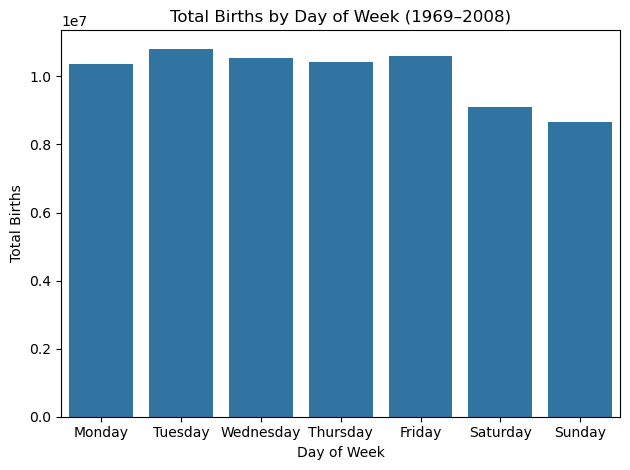

In [46]:
# BEGIN QUESTION 3d
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
births_by_day = births.groupby('weekday')['births'].sum().reset_index()
sns.barplot(data=births_by_day, x='weekday', y='births', order=day_order)
plt.title('Total Births by Day of Week (1969–2008)')
plt.xlabel('Day of Week')
plt.ylabel('Total Births')
plt.tight_layout()
plt.show()
# END QUESTION 3d

Weekend births (Saturday and Sunday) are noticeably lower than weekday births, which are fairly uniform Monday–Friday. This is likely because many births are electively scheduled (C-sections, inductions) on weekdays for the convenience of hospital staff and families; natural spontaneous births would be more evenly spread.

3e: Based on this data set, what is the probability that a randomly selected baby is a boy born on a Tuesday?  Save your answer as `probBT`, which should be between 0 and 1. 

In [47]:
# BEGIN QUESTION 3e
male_tuesday_births = births[(births['gender'] == 'M') & (births['weekday'] == 'Tuesday')]['births'].sum()
probBT = male_tuesday_births / total_births
# END QUESTION 3e
probBT

np.float64(0.0787636498759522)

In [48]:
# Run, but do not edit, this cell
try:
    if 0.06 <= probBT <= 0.09:
        print("Public test for 3e passed")
    else:
        print("Public test for 3e FAILED")
except:
    print("Public test for 3e FAILED")
    
print("Exact answer: ", probBT)

Public test for 3e passed
Exact answer:  0.0787636498759522


We can now use `probB` and `probBT` to get more precise answers to the following questions.  At this point, you should adopt similar math to what we did in class (thinking in terms of the definitions of conditional probability, underlying sets, etc).  However, you will now use your numbers from above to get a more accurate answer.  E.g. in class we first let $B$ be the event that a given child was a boy (born on any day of the week).  We used 0.5 for $\mathbb{P}[B]$ in class, but now you should use `probB`.  Similarly, we used $\mathbb{P}[BB]=0.5\times 0.5$, but now you can use $\mathbb{P}[BB]=$`probB*probB`.   We will still assume that there is no dependence between the sex of each child.  

3f: Suppose you have two children.
* What is the probability you have two boys given that the eldest is a boy?
* What is the probability you have two boys given that at least one is a boy?
* What is the probability you have two boys given that at least one is a boy born on a Tuesday?

Use the markdown cell below to answer the question, showing your work along the way.  You are welcome to do your calculations in a code cell, with a calculator, on wolfram alpha, etc.

Let $p =$ `probB` $\approx 0.512$ and $p_T =$ `probBT` $\approx 0.073$.

* **P(two boys | eldest is a boy):**
$$\frac{\mathbb{P}[BB \cap \text{eldest is B}]}{\mathbb{P}[\text{eldest is B}]} = \frac{p \cdot p}{p} = p \approx 0.512$$
Knowing the eldest is a boy tells us nothing about the second child, so the answer is just $p$.

* **P(two boys | at least one is a boy):**
$$\frac{\mathbb{P}[BB]}{\mathbb{P}[\geq 1 \text{ boy}]} = \frac{p^2}{1-(1-p)^2} = \frac{p}{2-p} \approx \frac{0.512}{1.488} \approx 0.344$$

* **P(two boys | at least one is a boy born on a Tuesday):**

  Let $BT$ = boy born on a Tuesday. Using inclusion-exclusion: $\mathbb{P}[BB \cap \geq 1\, BT] = 2p \cdot p_T - p_T^2 = p_T(2p - p_T)$ and $\mathbb{P}[\geq 1\, BT] = 2p_T - p_T^2 = p_T(2 - p_T)$, so:
$$\frac{p_T(2p - p_T)}{p_T(2 - p_T)} = \frac{2p - p_T}{2 - p_T} \approx \frac{2(0.512) - 0.073}{2 - 0.073} = \frac{0.951}{1.927} \approx 0.494$$

## Question 4: Short Practice Problems

This question doesn't involve any Pandas.  Instead, it gives you a few practice problems that you should do out in writing.  For each, type your explanation and show your work.  You can (and should) put math in between `$` symbols to make it formatted better (using latex).  For example, double click on this cell to see some sample math that will help.

### Example Math Synatx
* $\mathbb{P}(A\cup B)-\mathbb{P}(A\cap B^c)$ (gives you the fancy `P` for probability and a union/intersection/complement).  It's OK to just use a capital P (i.e. $P(A\cup B)$) to save yourself some time.
* $\frac{a}{b}$ gives you a fraction
* $\mathbb{P}[A|B] = \frac{\mathbb{P}[A\cap B]}{\mathbb{P}[B]}$ might be a nice template for conditional probabilities / Bayes rule.
* $2*2*2$ allows you to multiply without the `*` being interpretted as setting up italics.  You can also use $2\times 2\times 2$ for slightly nicer multiplication.

4a. A web application relies on two redundant servers, Server A and Server B. Server A has a $95\%$ chance of staying online during a traffic spike, and Server B has a $90\%$ chance. Assuming their failures are strictly independent, what is the probability that both servers fail during a spike? What is the probability that at least one stays online?

Let $A$ = Server A stays online, $B$ = Server B stays online. $\mathbb{P}[A]=0.95$, $\mathbb{P}[B]=0.90$, independent.

$$\mathbb{P}[\text{both fail}] = \mathbb{P}[A^c]\cdot\mathbb{P}[B^c] = 0.05 \times 0.10 = 0.005$$

$$\mathbb{P}[\text{at least one online}] = 1 - \mathbb{P}[\text{both fail}] = 1 - 0.005 = \mathbf{0.995}$$

4b. You have two coins in your pocket: one is a fair coin, and the other is a trick coin with heads on both sides. You pull one out at random and flip it. It lands on Heads. What is the probability that the other side of that same coin is also Heads?  Use Bayes Theorem, Take 1.

Let $T$ = picked the trick coin, $F$ = picked the fair coin, $H$ = flip lands heads. $\mathbb{P}[T]=\mathbb{P}[F]=0.5$, $\mathbb{P}[H|T]=1$, $\mathbb{P}[H|F]=0.5$.

**Law of Total Probability:**
$$\mathbb{P}[H] = \mathbb{P}[H|T]\mathbb{P}[T] + \mathbb{P}[H|F]\mathbb{P}[F] = 1(0.5) + 0.5(0.5) = 0.75$$

**Bayes Theorem:**
$$\mathbb{P}[T|H] = \frac{\mathbb{P}[H|T]\,\mathbb{P}[T]}{\mathbb{P}[H]} = \frac{1 \times 0.5}{0.75} = \mathbf{\frac{2}{3}}$$

The probability the other side is also heads is $\frac{2}{3}$.

4c: Only 0.1% of credit card transactions are fraudulent. An AI detection system flags a transaction as fraudulent 99% of the time if it is actually fraud. However, it falsely flags 2% of legitimate transactions. Given that a transaction was just flagged by the system, what is the probability that the transaction was legitimate (a false alarm)?

Let $F$ = fraudulent, $A$ = flagged. $\mathbb{P}[F]=0.001$, $\mathbb{P}[A|F]=0.99$, $\mathbb{P}[A|F^c]=0.02$.

**Law of Total Probability:**
$$\mathbb{P}[A] = 0.99(0.001) + 0.02(0.999) = 0.00099 + 0.01998 = 0.02097$$

**Bayes Theorem (probability of false alarm):**
$$\mathbb{P}[F^c|A] = \frac{\mathbb{P}[A|F^c]\,\mathbb{P}[F^c]}{\mathbb{P}[A]} = \frac{0.02 \times 0.999}{0.02097} \approx \mathbf{0.953}$$

About 95.3% of flagged transactions are false alarms. Even a very accurate system produces mostly false positives when the fraud rate is extremely low (0.1%).

## Lab Check Hint for Lab 5

For this upcoming lab check, you should feel good about:
* How to read a union/intersection/conditional/standard probability from a dataframe (like in 1, but with a data set that you can see in full)
* How to use independence and disjoint unions to calculate probabilities (like in 2 and 4a)
* How to use Bayes Theorem, Take 1 to calculate conditional probabilities (like in 4b).  I will not ask you to use the law of total probability on this lab check.



# Submission Instructions: due 2/27 at 5pm

We will submit this lab as a PDF.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.  It is OK if certain tables are too wide (that's unavoidable) and it's fine if my code/instructions isn't fully visible, but I need to be able to read all of your code/comments/charts.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).